# 1. Importar librerías

In [103]:
# Importamos librerias para EDA
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [104]:
# Importamos librerias para Machine Learning
# train_test_split para generar los conjuntos de training/testing
from sklearn.model_selection import train_test_split

# LinearRegression para generar el modelo de Regresión Lineal
from sklearn.linear_model import LinearRegression

# KNeighborsRegressor para generar el modelo de KNN
from sklearn.neighbors import KNeighborsRegressor

# métricas que usaremos para evaluar los modelos
from sklearn.metrics import (mean_squared_error, root_mean_squared_error,
                             mean_absolute_error, mean_absolute_percentage_error, r2_score)

# KFold, cross_val_score y GridSearchCV para validación cruzada y búsqueda de hiperparámetros
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV

# StandardScaler y Pipeline para escalar y encadenar pasos
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


# 2. Cargar el dataset

In [105]:
# Cargar dataset 
df_raw=pd.read_csv("https://raw.githubusercontent.com/UADE-Python-Data-Science/583433_repo_oficial/refs/heads/main/Datasets/diamonds_clean.csv")
df_raw.shape

(53794, 13)

In [106]:
SEMILLA = 42
N_SAMPLE = None # None para seleccionar todos los datos

In [107]:
# Seleccionamos 2 variables y 10 registros random (solo para el primer análisis)
if N_SAMPLE:
    df = df_raw[["carat", "price"]].sample(N_SAMPLE, random_state=SEMILLA).reset_index(drop=True)
else:
     df = df_raw[["carat", "price"]]

In [108]:
# Usamos .rename(...) sin inplace: así df es un DataFrame nuevo y no aparece el SettingWithCopyWarning
df = df.rename(columns={
    "carat": "quilates",
    "price": "precio"})
df.head()

,quilates,precio
0,0.23,326
1,0.21,326
2,0.23,327
3,0.29,334
4,0.31,335


# 3. EDA

In [109]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53794 entries, 0 to 53793
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   quilates  53794 non-null  float64
 1   precio    53794 non-null  int64  
dtypes: float64(1), int64(1)
memory usage: 840.7 KB


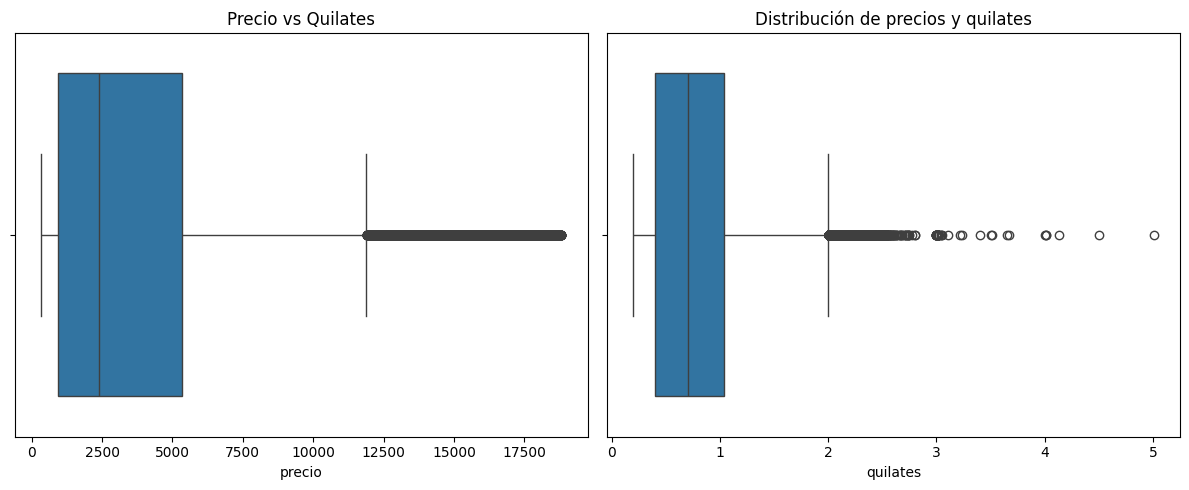

In [110]:
# Análisis univariado
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Boxplot precio
sns.boxplot(
    data=df,
    x="precio",
    ax=ax[0]
)
ax[0].set_title("Precio vs Quilates")

# Boxplor quilates
sns.boxplot(
    data=df,
    x="quilates",
    ax=ax[1]
)
ax[1].set_title("Distribución de precios y quilates")

plt.tight_layout()
plt.show()


In [111]:
# Calculamos la matriz de correlación
df.corr()

# Evaluar otras semillas y ver si cambia el Coeficiente


,quilates,precio
quilates,1.000000,0.921548
precio,0.921548,1.000000


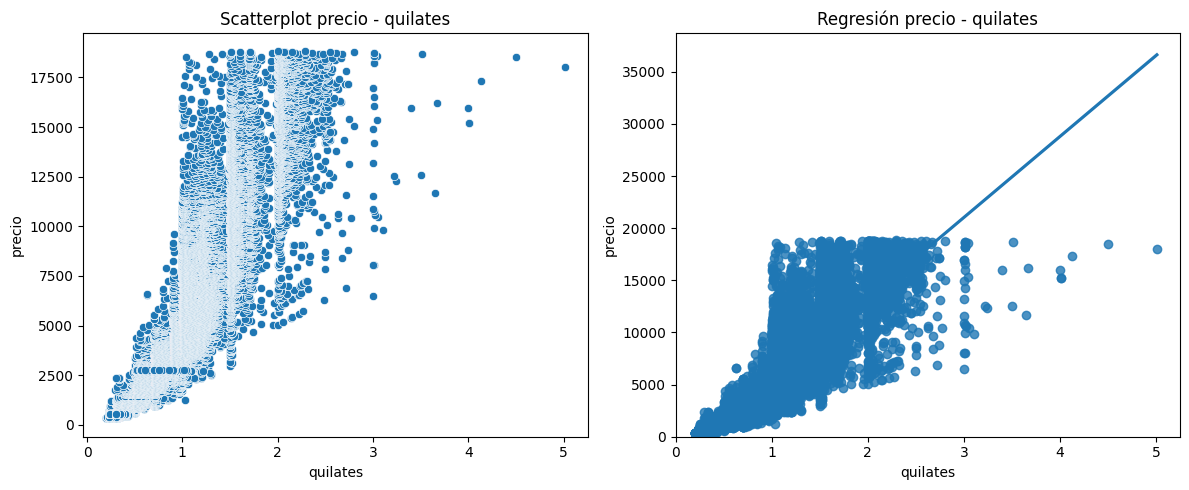

In [112]:
# Análisis bivariado
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Scatterplot precio - quilates
sns.scatterplot(
    data=df,
    x="quilates",
    y="precio",
    ax=ax[0]
)
ax[0].set_title("Scatterplot precio - quilates")

# LRecta de regresión
sns.regplot(
    data=df,
    x="quilates",
    y="precio",
    ax=ax[1]
)
ax[1].set_title("Regresión precio - quilates")
ax[1].set_xlim(left=0)
ax[1].set_ylim(bottom=0)


plt.tight_layout()
plt.show()

# 4. Modelo de regresión lineal simple usando scikit-learn

In [113]:
# Variables independientes o predictoras X
X = df[["quilates"]]

# Variable objetivo o variable respuesta y
y = df["precio"]

# Split manual - elegimos un 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA
)

In [148]:
# X_train

In [149]:
# y_train

In [116]:
# Crear el modelo
model_rl = LinearRegression()

In [117]:
# Entrenamos el modelo a partir de los datos de training
model_rl.fit(X_train, y_train)
# Internamente calcula b0 y b1

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[7762.54]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['quilates']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2258
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [118]:
# Extraemos del modelo los coeficientes b0 y b1
b1 = model_rl.coef_[0] # es el valor de la pendiente b1
b0 = model_rl.intercept_ # es el valor de la ordenada al origen b0

print(f"bo= {b0:.2f} \nb1= {b1:.2f}")

bo= -2257.95 
b1= 7762.54


In [119]:
# Usamos el modelo resultante para predecir los precios (y_predict) a partir de los quilates del conjunto de testing (X_test)
y_pred = model_rl.predict(X_test)

In [120]:
# Métricas
# Comparamos los precios predichos (y_pred) con los precios reales del conjunto de testing (y_test)
lr_r2 = r2_score(y_test, y_pred)
lr_mse = mean_squared_error(y_test, y_pred)
lr_rmse = root_mean_squared_error(y_test, y_pred)

print(f"LR R²:   {lr_r2:.3f}")
print(f"LR MSE:  {lr_mse:,.0f}  (en dólares²: difícil de interpretar)")
print(f"LR RMSE: {lr_rmse:,.0f} USD  (raíz del MSE: vuelve a dólares)")

LR R²:   0.848
LR MSE:  2,317,072  (en dólares²: difícil de interpretar)
LR RMSE: 1,522 USD  (raíz del MSE: vuelve a dólares)


In [121]:
# Guardamos la predicción de la regresión lineal en el DataFrame para mirarla
df["precio_reg_lineal"] = model_rl.predict(X).round(2)
df.sort_values(by="quilates", ascending=True)

,quilates,precio,precio_reg_lineal
31505,0.20,367,-705.44
31508,0.20,367,-705.44
31507,0.20,367,-705.44
31506,0.20,367,-705.44
31509,0.20,367,-705.44
...,...,...,...
25939,4.01,15223,28869.83
25940,4.01,15223,28869.83
27065,4.13,17329,29801.33
27563,4.50,18531,32673.47


**Observá las primeras filas (válido cuando se usan todos los datos):** para diamantes de 0.20 quilates la recta predice **precios negativos** (−705 USD).
La relación precio–quilates no es una recta: es una curva que se empina a medida que crecen los quilates. Vamos a ver si KNN, que no asume ninguna forma, lo resuelve mejor.

# 5. Modelo de regresión KNN usando scikit-learn

KNN no aprende una fórmula. Para predecir el precio de un diamante:

1. busca en train los **k diamantes con quilates más parecidos**,
2. y devuelve el **promedio de sus precios**.

Usamos el mismo split que en la regresión lineal (mismo `random_state`), así comparamos los dos modelos con exactamente los mismos diamantes de test.

In [122]:
# Variables independientes o predictoras X
X = df[["quilates"]]

# Variable objetivo o variable respuesta y
y = df["precio"]

# Split manual - elegimos un 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA
)

In [123]:
# Crear el modelo con k = 5 vecinos
model_knn = KNeighborsRegressor(n_neighbors=5)

# Entrenamos: KNN solo GUARDA los datos de train (no calcula b0 ni b1)
model_knn.fit(X_train, y_train)

# Predecimos sobre test
y_pred_knn = model_knn.predict(X_test)

## 5.1 ¿Cómo predice KNN? Un diamante de X_test

Tomamos un diamante de test, le pedimos al modelo sus 5 vecinos con `.kneighbors()` y verificamos que la predicción es el promedio de sus precios.

In [124]:
X_test

,quilates
43520,0.71
4264,0.90
47271,0.57
44300,0.51
13943,1.19
...,...
41659,0.52
43406,0.52
35681,0.32
25827,1.54


In [125]:
# Elegimos un diamante de test
i = 0
# se selecciona el diamente en posicion i de X_test
diamante = X_test.iloc[[i]]  # con doble corchete retorna un DataFrame (2D)

# kneighbors devuelve las distancias y las POSICIONES de los vecinos dentro de X_train
distancias, posiciones = model_knn.kneighbors(diamante)

vecinos = X_train.iloc[posiciones[0]].copy()
vecinos["precio"] = y_train.iloc[posiciones[0]].values
vecinos["distancia"] = distancias[0]


# Del diamante i, se extraen los quilates
quilates = diamante["quilates"].iloc[0]
# El precio real, esta en la serie y_test, misma posición i
precio_real = y_test.iloc[i]
# Se obtiene el precio con el modelo model_knn
precio_estimado = model_knn.predict(diamante)[0]
# Se calcula el precio promedio de los k vecinos
precio_vecinos_mean = vecinos["precio"].mean()

print(
    f"Diamante de test: {quilates} quilates, precio real {precio_real} |  estimado por KNN {precio_estimado}|  promedio vecinos {precio_vecinos_mean} USD\n"
)
vecinos

Diamante de test: 0.71 quilates, precio real 1435 |  estimado por KNN 2208.8|  promedio vecinos 2208.8 USD



,quilates,precio,distancia
47810,0.71,1917,0.0
52103,0.71,2487,0.0
51011,0.71,2345,0.0
50308,0.71,2264,0.0
48704,0.71,2031,0.0


**¡Los 5 vecinos tienen exactamente los mismos quilates (distancia 0)!**

En train hay más de 40.000 diamantes pero solo ~270 valores distintos de quilates, así que hay cientos de diamantes "empatados" en cada valor. Con una sola variable, KNN con k=5 elige 5 de ellos (cuáles, depende de cómo están ordenados los datos) y los promedia. Lo vemos en un gráfico:

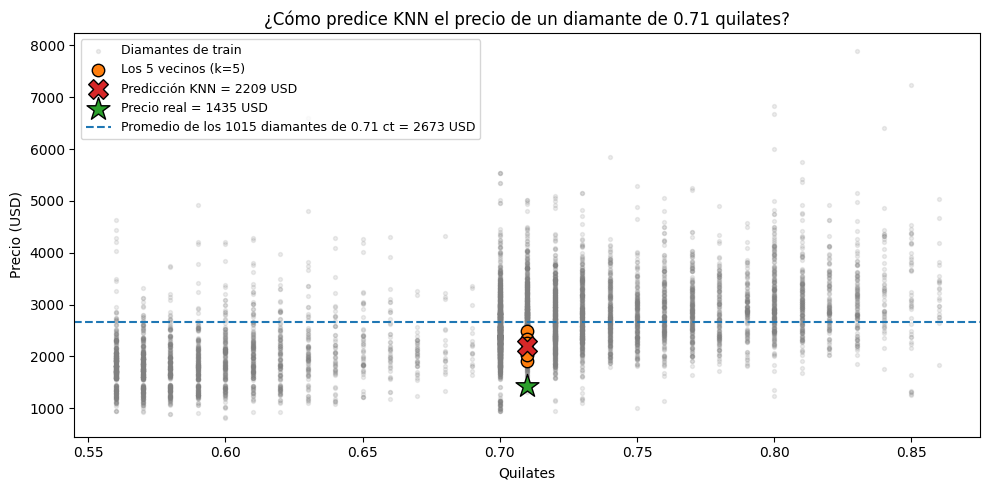

In [126]:
# Todos los diamantes de train con los mismos quilates que nuestro diamante de test
mismos_quilates = y_train[X_train["quilates"] == quilates]

fig, ax = plt.subplots(figsize=(10, 5))

# Contexto: diamantes de train cercanos (±0.15 quilates)
cerca = X_train["quilates"].between(quilates - 0.15, quilates + 0.15)
ax.scatter(X_train.loc[cerca, "quilates"], y_train[cerca], s=8, alpha=0.15, color="gray",
           label="Diamantes de train")

# Los 5 vecinos elegidos
ax.scatter(vecinos["quilates"], vecinos["precio"], s=80, color="tab:orange",
           edgecolor="black", zorder=3, label="Los 5 vecinos (k=5)")

# Predicción = promedio de los vecinos
ax.scatter(quilates, vecinos["precio"].mean(), marker="X", s=200, color="tab:red",
           edgecolor="black", zorder=4, label=f"Predicción KNN = {vecinos['precio'].mean():.0f} USD")

# Precio real del diamante de test
ax.scatter(quilates, precio_real, marker="*", s=300, color="tab:green",
           edgecolor="black", zorder=4, label=f"Precio real = {precio_real} USD")

# Promedio de TODOS los diamantes con esos quilates
ax.axhline(mismos_quilates.mean(), color="tab:blue", linestyle="--",
           label=f"Promedio de los {len(mismos_quilates)} diamantes de {quilates} ct = {mismos_quilates.mean():.0f} USD")

ax.set_title(f"¿Cómo predice KNN el precio de un diamante de {quilates} quilates?")
ax.set_xlabel("Quilates")
ax.set_ylabel("Precio (USD)")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

Este gráfico anticipa la idea central de la sección 7: con k=5 la predicción depende de **qué 5** diamantes tocaron entre cientos iguales. Si aumentamos k, la predicción se acerca a la línea azul punteada: el **precio promedio de todos los diamantes de ese tamaño**, que es una estimación mucho más estable.

## 5.2 Graficar el modelo completo: curva KNN vs recta de regresión

Para la regresión lineal graficamos la recta. Para KNN no hay fórmula, pero podemos hacer lo mismo de otra forma: **pedirle predicciones para una grilla de quilates** (de 0.2 a 5) y unir los puntos.

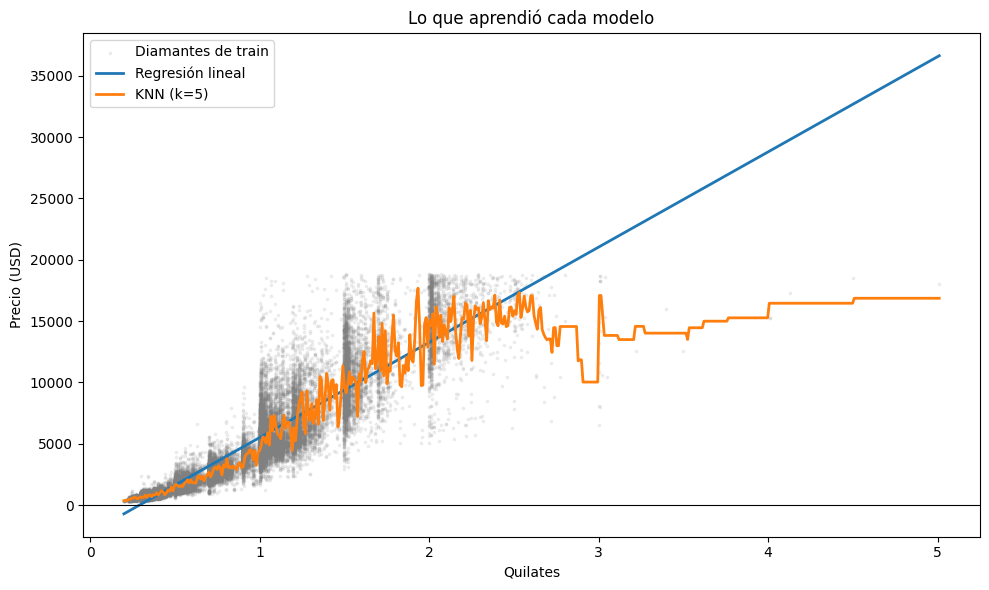

In [145]:
# Grilla de quilates: 500 valores entre el mínimo y el máximo
grilla = pd.DataFrame({"quilates": np.linspace(X["quilates"].min(), X["quilates"].max(), 500)})

grilla["pred_rl"] = model_rl.predict(grilla[["quilates"]])
grilla["pred_knn"] = model_knn.predict(grilla[["quilates"]])

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(X_train["quilates"], y_train, s=3, alpha=0.1, color="gray", label="Diamantes de train")
ax.plot(grilla["quilates"], grilla["pred_rl"], color="tab:blue", linewidth=2, label="Regresión lineal")
ax.plot(grilla["quilates"], grilla["pred_knn"], color="tab:orange", linewidth=2, label="KNN (k=5)")
ax.axhline(0, color="black", linewidth=0.8)

ax.set_title("Lo que aprendió cada modelo")
ax.set_xlabel("Quilates")
ax.set_ylabel("Precio (USD)")
ax.legend()
plt.tight_layout()
plt.show()

**Qué muestra el gráfico:**

- La **recta** no puede curvarse: subestima los diamantes medianos, sobreestima los grandes y da precios negativos para los chicos.
- **KNN sigue la forma de la nube**, porque cada predicción es un promedio local. Pero con k=5 la curva es **dentada**: copia el ruido de los pocos vecinos que le tocaron.
- A partir de ~3 quilates casi no hay diamantes: ahí KNN promedia vecinos lejanos y la curva se vuelve escalonada.

# 6. Métricas: ¿con qué medimos el error?

**Primero, una aclaración importante:** *accuracy* (porcentaje de aciertos) es una métrica de **clasificación**. Acá predecimos un número (el precio), así que es un problema de **regresión**: nunca vamos a "acertar" un precio exacto, lo que medimos es **cuánto nos equivocamos**.

| Métrica | Fórmula (idea) | Unidades | Cómo se lee |
|---|---|---|---|
| **MSE** | promedio de los errores² | USD² | Difícil de interpretar; sirve para optimizar |
| **RMSE** | √MSE | USD | "Error típico" en dólares. Castiga más los errores grandes |
| **MAE** | promedio de \|error\| | USD | Error promedio en dólares. Más fácil de explicar |
| **MAPE** | promedio de \|error\| / real | % | Error **relativo**: 800 USD de error no es lo mismo en un diamante de 500 que en uno de 15.000 |
| **R²** | 1 − MSE modelo / MSE de predecir la media | sin unidad | Proporción de la variabilidad explicada (1 = perfecto, 0 = igual que predecir la media) |

Armamos una función para no repetir código y calcular todas juntas.

In [128]:
def evaluar(nombre, y_real, y_predicho):
    """Devuelve un diccionario con las métricas de regresión de un modelo."""
    return {
        "modelo": nombre,
        "RMSE": root_mean_squared_error(y_real, y_predicho),
        "MAE": mean_absolute_error(y_real, y_predicho),
        "MAPE (%)": mean_absolute_percentage_error(y_real, y_predicho) * 100,
        "R²": r2_score(y_real, y_predicho),
    }

In [129]:
# Baseline: predecir siempre el precio promedio de train
y_pred_media = np.full(len(y_test), y_train.mean())

resultados = pd.DataFrame([
    evaluar("Media (baseline)", y_test, y_pred_media),
    evaluar("Regresión lineal", y_test, y_pred),
    evaluar("KNN (k=5)", y_test, y_pred_knn),
])
resultados.round(2)

,modelo,RMSE,MAE,MAPE (%),R²
0,Media (baseline),3904.56,2969.62,185.50,-0.00
1,Regresión lineal,1522.19,996.67,38.06,0.85
2,KNN (k=5),1519.29,870.61,22.21,0.85


**Las métricas cuentan historias distintas:**

- Por **RMSE**, KNN y regresión lineal están casi empatados (~1.500 USD).
- Por **MAPE**, KNN es mucho mejor (~22% vs ~38%). ¿Por qué? La regresión lineal se equivoca mucho en los diamantes **chicos y baratos** (hasta da precios negativos). En dólares esos errores son pequeños y el RMSE casi no los ve, pero en porcentaje son enormes.
- Ninguna métrica es "la correcta": cada una responde una pregunta distinta. Por eso conviene mirar más de una y **siempre contra el baseline**.

In [130]:
# ¿Cuántas predicciones negativas hace cada modelo en test?
print("Predicciones negativas RL: ", (y_pred < 0).sum())
print("Predicciones negativas KNN:", (y_pred_knn < 0).sum())

Predicciones negativas RL:  333
Predicciones negativas KNN: 0


# 7. Los hiperparámetros de KNN

Un **hiperparámetro** es una decisión que tomamos **nosotros antes de entrenar** (no la aprende el modelo con `fit`). Los principales de `KNeighborsRegressor`:

| Hiperparámetro | Default | Qué controla |
|---|---|---|
| `n_neighbors` | 5 | **Cuántos vecinos** se promedian. Es el más importante |
| `weights` | `"uniform"` | `"uniform"`: todos los vecinos pesan igual. `"distance"`: los más cercanos pesan más |
| `metric` / `p` | `"minkowski"`, `p=2` | Cómo se mide la distancia. `p=2` es la distancia euclidiana (en línea recta), `p=1` es la Manhattan (suma de diferencias) |
| `algorithm`, `leaf_size` | `"auto"`, 30 | Solo afectan la **velocidad** de búsqueda, no el resultado |

**Ojo con una sola variable:** la distancia entre 0.5 y 0.7 quilates es 0.2 con cualquier métrica, así que `metric` y `p` no cambian nada todavía. Van a importar cuando agreguemos una segunda variable (sección 9).

In [131]:
# Comprobación: con 1 variable, p=1 y p=2 dan el mismo resultado
for p in [1, 2]:
    m = KNeighborsRegressor(n_neighbors=5, p=p).fit(X_train, y_train)
    print(f"p={p} -> RMSE {root_mean_squared_error(y_test, m.predict(X_test)):.1f}")

p=1 -> RMSE 1519.3
p=2 -> RMSE 1519.3


## 7.1 El efecto de k, en un gráfico

Entrenamos 4 modelos con distintos k y graficamos la curva de cada uno.

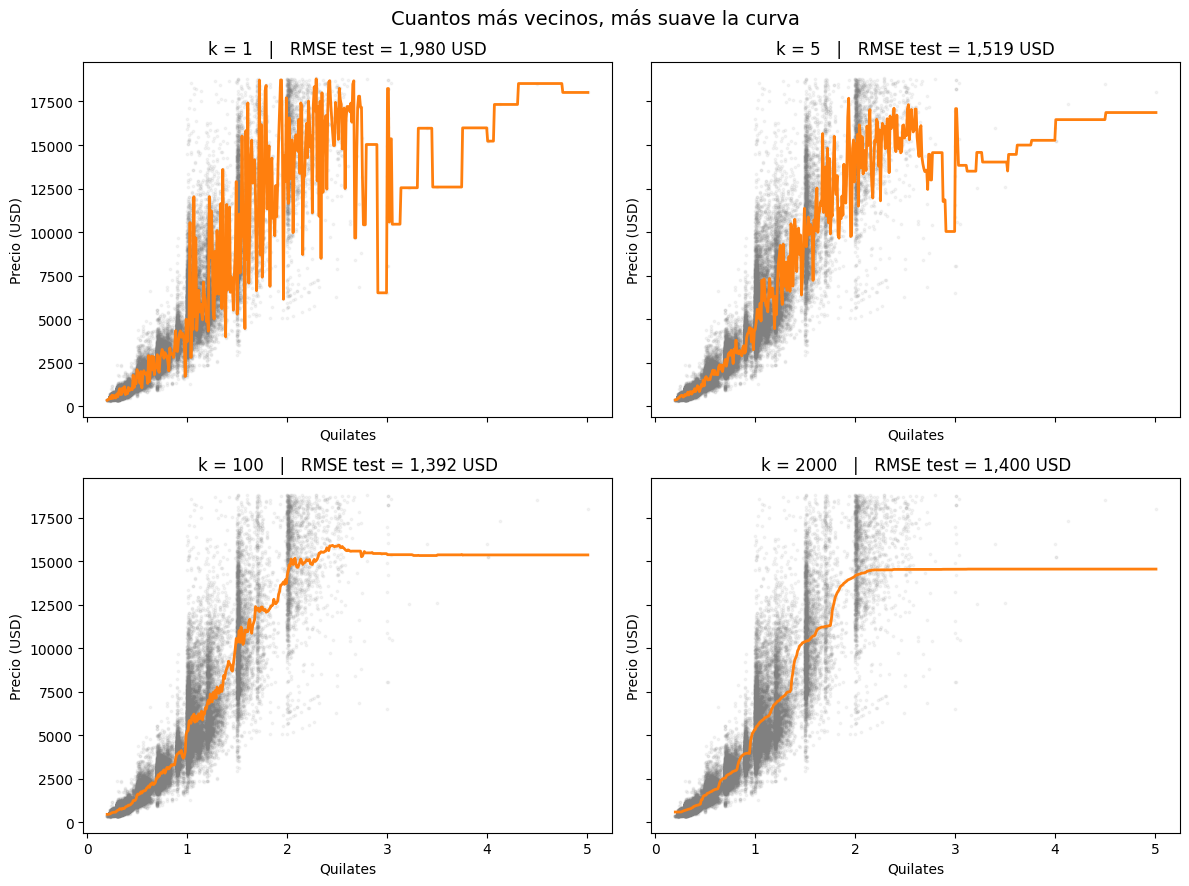

In [132]:
valores_k = [1, 5, 100, 2000]

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)

for ax, k in zip(axes.flatten(), valores_k):
    m = KNeighborsRegressor(n_neighbors=k).fit(X_train, y_train)
    rmse = root_mean_squared_error(y_test, m.predict(X_test))

    ax.scatter(X_train["quilates"], y_train, s=3, alpha=0.08, color="gray")
    ax.plot(grilla["quilates"], m.predict(grilla[["quilates"]]), color="tab:orange", linewidth=2)
    ax.set_title(f"k = {k}   |   RMSE test = {rmse:,.0f} USD")
    ax.set_xlabel("Quilates")
    ax.set_ylabel("Precio (USD)")

plt.suptitle("Cuantos más vecinos, más suave la curva", fontsize=14)
plt.tight_layout()
plt.show()

- **k = 1 (sobreajuste):** copia el precio de un solo diamante. La curva salta todo el tiempo y el error es el más alto.
- **k = 5:** todavía ruidosa.
- **k = 100:** suave y sigue bien la forma. Con cientos de diamantes por valor de quilates, promediar 100 es estimar "el precio típico de ese tamaño".
- **k = 2000 (subajuste):** en la zona de diamantes grandes, donde hay pocos, tiene que ir a buscar vecinos muy lejanos (más chicos y más baratos) y **aplana la curva**.

Hay un punto medio. ¿Cómo lo elegimos sin hacer trampa? Eso es la validación cruzada.

# 8. Elegir k con validación cruzada (5-fold)

**¿Por qué no elegir el k con mejor RMSE en test?** Porque test es el "examen final". Si probamos 20 valores de k y elegimos el que mejor da en test, el test dejó de ser un examen sorpresa: lo usamos para tomar decisiones y su error queda **optimista**.

**La idea de K-Fold:** usamos solo train. Lo partimos en 5 partes (*folds*) y entrenamos 5 veces:

```
Ronda 1: [VALID][train][train][train][train]
Ronda 2: [train][VALID][train][train][train]
Ronda 3: [train][train][VALID][train][train]
Ronda 4: [train][train][train][VALID][train]
Ronda 5: [train][train][train][train][VALID]
```

Cada diamante de train se usa 4 veces para entrenar y 1 vez para validar. El resultado es el **promedio de los 5 errores**: más confiable que un único split. El test **no se toca** hasta el final.

## 8.1 Validación cruzada para un solo modelo

In [133]:
# shuffle=True mezcla los datos antes de partirlos (el CSV viene ordenado por precio)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# scikit-learn siempre MAXIMIZA el score, por eso los errores vienen con signo negativo
scores = cross_val_score(
    KNeighborsRegressor(n_neighbors=5), X_train, y_train,
    cv=kfold, scoring="neg_root_mean_squared_error"
)

print("RMSE de cada fold:", (-scores).round(0))
print(f"RMSE promedio: {-scores.mean():.0f} ± {scores.std():.0f} USD")

RMSE de cada fold: [1544. 1547. 1524. 1555. 1576.]
RMSE promedio: 1549 ± 17 USD


## 8.2 GridSearchCV: probar muchas combinaciones

`GridSearchCV` repite lo anterior para **cada combinación** de hiperparámetros que le pasemos y se queda con la mejor.

In [134]:
grilla_param = {
    "n_neighbors": [1, 5, 10, 25, 50, 100, 200, 400, 1000],
    "weights": ["uniform", "distance"],
}

busqueda = GridSearchCV(
    KNeighborsRegressor(),
    param_grid=grilla_param,
    cv=kfold,
    scoring="neg_root_mean_squared_error",
)
busqueda.fit(X_train, y_train)   # 9 valores de k x 2 weights x 5 folds = 90 entrenamientos

print("Mejores hiperparámetros:", busqueda.best_params_)
print(f"RMSE de validación:       {-busqueda.best_score_:.0f} USD")

Mejores hiperparámetros: {'n_neighbors': 200, 'weights': 'uniform'}
RMSE de validación:       1433 USD


In [135]:
# Pasamos los resultados a un DataFrame (los scores negativos los volvemos positivos)
cv_res = pd.DataFrame(busqueda.cv_results_)
cv_res = cv_res[["param_n_neighbors", "param_weights", "mean_test_score", "std_test_score"]]
cv_res = cv_res.rename(columns={
    "param_n_neighbors": "k",
    "param_weights": "weights",
    "mean_test_score": "RMSE_validacion",
    "std_test_score": "desvio_validacion",
})
cv_res["RMSE_validacion"] = -cv_res["RMSE_validacion"]
cv_res.round(1)

,k,weights,RMSE_validacion,desvio_validacion
0,1,uniform,1987.0,48.3
1,1,distance,1987.0,48.3
2,5,uniform,1549.0,16.8
3,5,distance,1553.9,15.5
4,10,uniform,1504.9,13.3
5,10,distance,1512.8,12.5
6,25,uniform,1459.0,11.3
7,25,distance,1468.5,9.3
8,50,uniform,1442.4,11.8
9,50,distance,1454.0,7.1


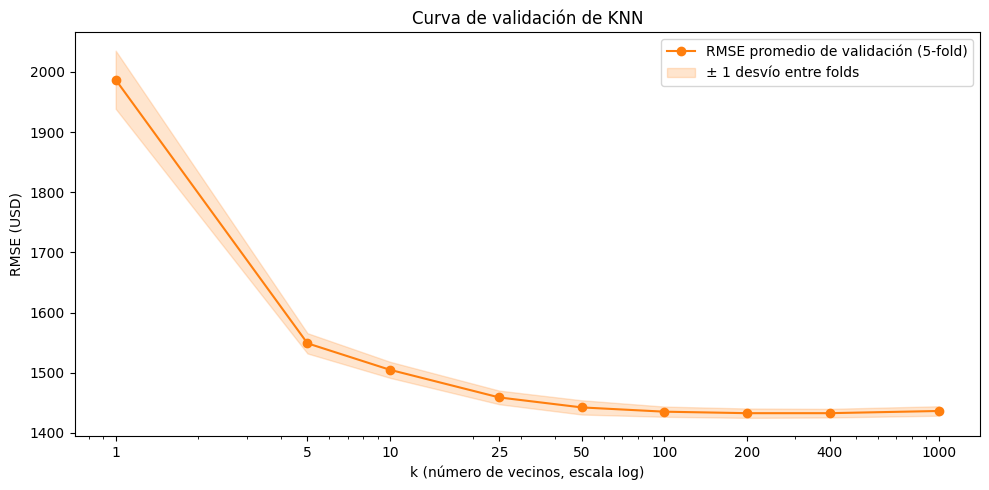

In [136]:
# Curva de validación: error vs k (solo weights="uniform")
uniforme = cv_res[cv_res["weights"] == "uniform"]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(uniforme["k"], uniforme["RMSE_validacion"], marker="o", color="tab:orange", label="RMSE promedio de validación (5-fold)")
# banda de ± 1 desvío entre folds
ax.fill_between(uniforme["k"],
                uniforme["RMSE_validacion"] - uniforme["desvio_validacion"],
                uniforme["RMSE_validacion"] + uniforme["desvio_validacion"],
                color="tab:orange", alpha=0.2, label="± 1 desvío entre folds")
ax.set_xscale("log")   # escala logarítmica: los valores de k van de 1 a 1000
ax.set_xticks(uniforme["k"])
ax.set_xticklabels(uniforme["k"])
ax.set_title("Curva de validación de KNN")
ax.set_xlabel("k (número de vecinos, escala log)")
ax.set_ylabel("RMSE (USD)")
ax.legend()
plt.tight_layout()
plt.show()

**Cómo leer la curva:**

- **A la izquierda (k chico):** error alto y muy variable entre folds (la banda es ancha en k=1) → el modelo copia el ruido de unos pocos diamantes (**sobreajuste**).
- **A la derecha (k = 1000):** el error vuelve a subir → el modelo promedia diamantes demasiado distintos (**subajuste**).
- **Entre k ≈ 100 y 400 la curva es casi plana:** las diferencias son de pocos dólares, menores que el desvío entre folds. Cuando hay empate práctico, una buena regla es elegir el valor **más simple o más rápido**.
- `weights="distance"` no ayuda acá: con tantos diamantes empatados en distancia 0, ponderar por distancia casi no cambia nada.

## 8.3 Evaluación final en test (una sola vez)

`GridSearchCV` ya re-entrenó el mejor modelo con **todo** train (`refit=True` por defecto). Ahora sí lo evaluamos en test.

In [137]:
model_knn_cv = busqueda.best_estimator_
y_pred_knn_cv = model_knn_cv.predict(X_test)

k_mejor = busqueda.best_params_["n_neighbors"]
resultados = pd.DataFrame([
    evaluar("Media (baseline)", y_test, y_pred_media),
    evaluar("Regresión lineal", y_test, y_pred),
    evaluar("KNN (k=5)", y_test, y_pred_knn),
    evaluar(f"KNN (k={k_mejor}, elegido con CV)", y_test, y_pred_knn_cv),
])
resultados.round(2)

,modelo,RMSE,MAE,MAPE (%),R²
0,Media (baseline),3904.56,2969.62,185.50,-0.00
1,Regresión lineal,1522.19,996.67,38.06,0.85
2,KNN (k=5),1519.29,870.61,22.21,0.85
3,"KNN (k=200, elegido con CV)",1391.20,799.14,20.94,0.87


# 9. ¿Mejora KNN si agregamos el corte (`cut`)?

El corte describe la calidad del tallado: **Fair < Good < Very Good < Premium < Ideal**. Esperaríamos que, a igual tamaño, un mejor corte valga más.

## 9.1 EDA: una trampa en los datos

In [138]:
orden_corte = ["Fair", "Good", "Very Good", "Premium", "Ideal"]

df_corte = df_raw[["carat", "cut", "price"]].rename(columns={
    "carat": "quilates", "cut": "corte", "price": "precio"})

# Mediana de precio y de quilates por corte
df_corte.groupby("corte")[["precio", "quilates"]].median().loc[orden_corte]

,precio,quilates
corte,,
Fair,3282.0,1.00
Good,3042.0,0.82
Very Good,2647.0,0.71
Premium,3182.0,0.86
Ideal,1813.0,0.54


**¡Los diamantes *Ideal* tienen el precio mediano más bajo!** ¿El mejor corte vale menos? No: los *Ideal* son, en promedio, **más chicos** (0.54 quilates contra 1.00 de los *Fair*). El tamaño es una **variable de confusión**: si comparamos el precio sin tener en cuenta los quilates, sacamos una conclusión al revés.

Para ver el efecto real del corte hay que comparar **a igual tamaño**. Eso es justamente lo que hace KNN con las dos variables: busca vecinos con quilates parecidos **y** corte parecido.

In [139]:
# Comparamos a igual tamaño: diamantes de exactamente 1.01 quilates
df_corte[df_corte["quilates"] == 1.01].groupby("corte")["precio"].median().loc[orden_corte]

corte
Fair         4276.0
Good         4818.5
Very Good    5294.0
Premium      5006.0
Ideal        5482.0
Name: precio, dtype: float64

A igual tamaño el orden se da vuelta: el *Fair* es el más barato y el *Ideal* el más caro. El orden de los cortes intermedios no es perfecto, porque el precio también depende de otras variables (color, claridad) que no estamos mirando.

## 9.2 Preparar la variable: de texto a número

KNN calcula distancias, así que necesita números. Como el corte tiene un **orden** natural, lo convertimos a 0, 1, 2, 3, 4 con `.map()` de pandas.

In [146]:
codigo_corte = {"Fair": 0, "Good": 1, "Very Good": 2, "Premium": 3, "Ideal": 4}
df_corte["corte_num"] = df_corte["corte"].map(codigo_corte)

X2 = df_corte[["quilates", "corte_num"]]
y2 = df_corte["precio"]

# Mismo split (mismo random_state y mismas filas) -> mismos diamantes en test que antes
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=SEMILLA)

print("¿Mismos diamantes en test?", (X2_test.index == X_test.index).all())
X2_train.describe().round(2)

¿Mismos diamantes en test? True


,quilates,corte_num
count,43035.00,43035.00
mean,0.80,2.90
std,0.48,1.11
min,0.20,0.00
25%,0.40,2.00
50%,0.70,3.00
75%,1.04,4.00
max,5.01,4.00


## 9.3 Escalar con un Pipeline

Ahora tenemos dos columnas en escalas distintas: los quilates varían poco (desvío ≈ 0.47) y el corte va de 0 a 4 (desvío ≈ 1.1). Sin escalar, **un salto de un nivel de corte pesaría en la distancia lo mismo que 1 quilate entero**. Escalamos para que las dos columnas hablen el mismo idioma.

Un `Pipeline` encadena el escalado y el modelo en un solo objeto:

- `pipe.fit(X_train, y_train)`: el scaler calcula media y desvío **solo con train**, transforma y entrena KNN.
- `pipe.predict(X_test)`: transforma test con **esa misma** media y desvío y predice.

Además, dentro de `GridSearchCV` el scaler se re-ajusta en cada fold, así el fold de validación nunca "se filtra" en el escalado.

In [141]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor()),
])

# Para referirnos a un hiperparámetro de un paso del pipeline: nombre_del_paso__parametro
grilla_pipe = {
    "knn__n_neighbors": [5, 10, 25, 50, 100, 200, 400],
    "knn__p": [1, 2],   # ahora que hay 2 variables, la métrica sí puede importar
}

busqueda_corte = GridSearchCV(pipe, grilla_pipe, cv=kfold, scoring="neg_root_mean_squared_error")
busqueda_corte.fit(X2_train, y2_train)

print("Mejores hiperparámetros:", busqueda_corte.best_params_)
print(f"RMSE de validación:       {-busqueda_corte.best_score_:.0f} USD")

Mejores hiperparámetros: {'knn__n_neighbors': 100, 'knn__p': 2}
RMSE de validación:       1379 USD


In [142]:
y_pred_knn_corte = busqueda_corte.best_estimator_.predict(X2_test)

k_corte = busqueda_corte.best_params_["knn__n_neighbors"]
resultados = pd.DataFrame([
    evaluar("Media (baseline)", y_test, y_pred_media),
    evaluar("Regresión lineal", y_test, y_pred),
    evaluar("KNN (k=5)", y_test, y_pred_knn),
    evaluar(f"KNN (k={k_mejor}, CV)", y_test, y_pred_knn_cv),
    evaluar(f"KNN quilates + corte (k={k_corte}, CV)", y2_test, y_pred_knn_corte),
])
resultados.round(2)

,modelo,RMSE,MAE,MAPE (%),R²
0,Media (baseline),3904.56,2969.62,185.50,-0.00
1,Regresión lineal,1522.19,996.67,38.06,0.85
2,KNN (k=5),1519.29,870.61,22.21,0.85
3,"KNN (k=200, CV)",1391.20,799.14,20.94,0.87
4,"KNN quilates + corte (k=100, CV)",1342.79,771.77,20.06,0.88


## 9.4 Graficar el modelo con corte

Con dos variables ya no hay una sola curva: hay **una curva por cada corte**. Usamos la misma idea de la grilla, repitiendo los quilates para cada nivel de corte.

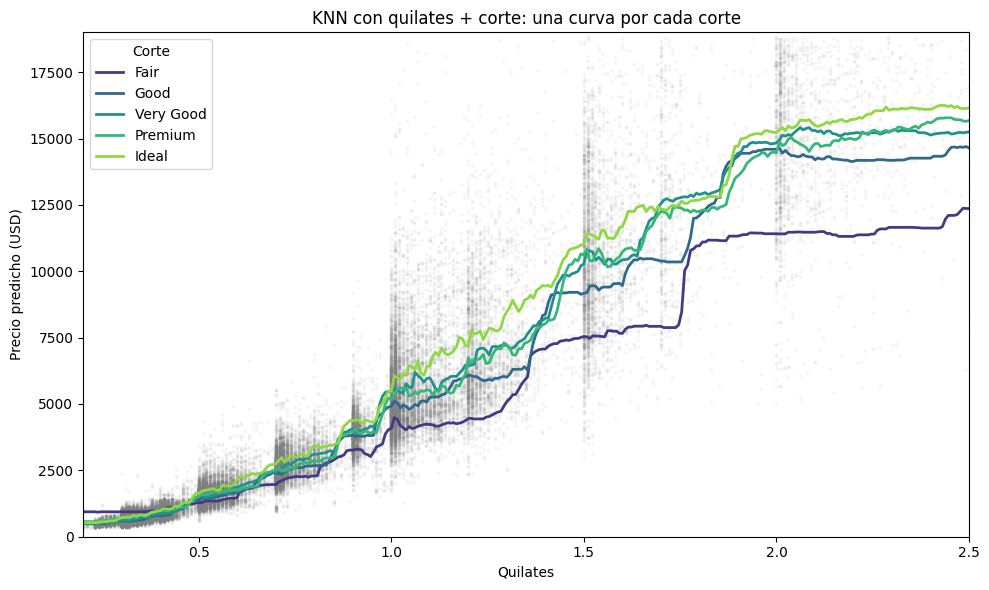

In [147]:
modelo_corte = busqueda_corte.best_estimator_
paleta = sns.color_palette("viridis", n_colors=5)   # paleta ordenada: el corte tiene orden

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(X_train["quilates"], y_train, s=3, alpha=0.05, color="gray")

for corte, color in zip(orden_corte, paleta):
    grilla_c = pd.DataFrame({
        "quilates": np.linspace(0.2, 2.5, 300),
        "corte_num": codigo_corte[corte],
    })
    ax.plot(grilla_c["quilates"], modelo_corte.predict(grilla_c), color=color, linewidth=2, label=corte)

ax.set_xlim(0.2, 2.5)
ax.set_ylim(0, 19000)
ax.set_title("KNN con quilates + corte: una curva por cada corte")
ax.set_xlabel("Quilates")
ax.set_ylabel("Precio predicho (USD)")
ax.legend(title="Corte")
plt.tight_layout()
plt.show()

**Conclusiones:**

- Agregar el corte **mejora un poco** el modelo: el RMSE baja alrededor de un 3% (de ~1.390 a ~1.345 USD) y el MAPE también. A igual tamaño, el corte aporta información, pero mucho menos que los quilates.
- En el gráfico, el *Fair* (violeta oscuro) queda por debajo del resto a partir de ~0.5 quilates: a igual tamaño, un mal corte vale menos, al revés de lo que sugería la tabla de medianas.
- Si sacamos el `StandardScaler` el resultado casi no cambia. Con 40.000 diamantes casi siempre hay vecinos con **los mismos quilates y el mismo corte**, así que la escala no altera quiénes son los vecinos. En otros datasets, con menos datos o columnas en escalas muy distintas (metros vs. milímetros, pesos vs. porcentajes), escalar cambia todo.

## Actividad

1. Repetí la sección 9 reemplazando `cut` por `clarity` (orden: `I1 < SI2 < SI1 < VS2 < VS1 < VVS2 < VVS1 < IF`). ¿Mejora más o menos que con el corte?
2. Probá con `color` (orden: `J < I < H < G < F < E < D`).
3. ¿Qué pasa si sacás el `StandardScaler` del pipeline? ¿Cambia el RMSE?